Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Lineage-restricted metaclonal state responses

## Scope and analysis plan
This is the requested lineage-specific counterpart of the overall state-response heatmap. It applies the already checked scalar family-aware estimator to all 17 frozen WT metaclones, two mutant conditions, two post-induction days, and five stored overlapping lineage masks. The registry contains **340 planned contrasts**, with one global Benjamini–Hochberg family across all of them. No UMAP, pseudotime, masks, metaclones, RNA models, or branch membership is fitted or changed. No composition or between-branch interaction test is added. Day 7 remains the shared WT reference; all contrasts compare a mutant condition with WT at the same later day.

The outcome is mean stored pseudotime among cells carrying a given lineage mask, not speed, maturation rate, branch entry, or terminal fate. Each lineage-family/sample/condition contributes one mean. The masks overlap: a cell or lineage family may contribute to several panels, so their cell and family supports are not additive. The original mask-fitting recipe remains an upstream documentation gap; these results are conditional on those fixed masks and the fixed WT partition.

## Estimator, eligibility and uncertainty
For contributing sequencing sample s, condition a, and family g, average the stored cell pseudotimes within that family/sample/condition/lineage subset to obtain y_gas. A sample contributes if each condition contains at least two family rows. The existing point-estimation rule additionally requires at least ten cells and three family/sample rows in each condition before common-sample selection. Let n_as be the family count in a contributing sample and w_s = min(n_WT,s,n_mut,s) / sum_s min(n_WT,s,n_mut,s). The estimate is

$\hat\Delta = \sum_s w_s(\bar y_{mut,s}-\bar y_{WT,s})$.

Weights are fixed at their observed values. Centered condition/sample residual contributions are divided by their condition/sample family count and multiplied by the signed weight, then summed over every sample and condition for each original lineage-family ID. In particular, sister clones identified by the same ancestral family across conditions share one uncertainty unit. A sister-clone match is not required for every family: all observed eligible families contribute, and the number shared across conditions is reported.

If u_g is that summed family influence, the cluster variance is G/(G−1) × sum_g u_g². Inference requires at least five distinct families in each condition, at least ten in their union, and nonzero influence variance. Otherwise the point estimate is retained when eligible, but uncertainty and P/q values are not reported. Pointwise 95% t intervals use G−1 degrees of freedom. Two-sided P values use 9,999 centered Rademacher multiplier draws, with one multiplier per family shared over all its contributing records. This is conditional, asymptotic sampling calibration, not an exact randomized-label test or independent biological replication. Biological replicate and sex are not included as covariates, as requested.

The original MC3 seeds 20261100–20261119 are retained to reproduce its 20 raw P values exactly. Other metaclones receive deterministic, distinct seeds specified in the saved registry. Unsupported tests count as P=1 only while constructing the fixed global BH denominator; their reported P and q remain missing. The old 20-test q values are supplied solely for reconciliation and are not used for stars. Double asterisks denote q340<0.05 and single asterisks 0.05≤q340<0.10. Gray means no point estimate; hatching means a point estimate with insufficient inferential support or zero variance.

## Environment and reproduction
Environment: **chronoclone**, existing Conda-managed installation `/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone`. No installation or environment mutation. The first cell prints versions and the absolute execution command. The builder extracts only the existing scalar function's source text into a visible code cell; it does not execute or import the source notebook. Every new plot has its full filtering, matrices, construction, export and display in a separate cell.


In [1]:

from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata as metadata, ast
import numpy as np, pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from IPython.display import display
ROOT=Path('/path/to/ChronoClone')
O=ROOT/'analysis_workspace/singh/singh_lineage_state_responses_20260911'
SRC=ROOT/'analysis_workspace/singh/singh_reference_response_20260911/dynamics'
for folder in ['tables','panels','reports']:(O/folder).mkdir(parents=True,exist_ok=True)
ENV=Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).parent.parent==ENV
environment={'name':'chronoclone','manager':'existing Conda-managed installation; unchanged','path':str(ENV),'kernel':'chronoclone','Python':platform.python_version(),'versions':{p:metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','nbformat','nbclient']},'execution_command':f'{ENV}/bin/python {O}/execute_notebook.py {O}/0001_lineage_state_responses.ipynb'}
display(environment)
(O/'reports/environment.json').write_text(json.dumps(environment,indent=2))
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
inputs=[SRC/'tables/cells_resolved.csv',SRC/'tables/lineage_family_registry.csv',SRC/'tables/mc3_branch_effects.csv',SRC/'tables/mc3_branch_sample_support.csv',SRC/'tables/mc3_branch_family_rows.csv',SRC/'0001_family_aware_responses.ipynb',SRC/'0002_mc3_branch_responses.ipynb',SRC/'build_branch_notebook.py',O/'build_notebook.py',O/'execute_notebook.py',ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811/tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv']
source_hashes={str(p.relative_to(ROOT)):sha(p) for p in inputs}
pd.DataFrame([{'path':p,'sha256':h} for p,h in source_hashes.items()]).to_csv(O/'reports/source_manifest.csv',index=False)
MCS=['0','1','2','3','4','5','6','7','9','10','11','12','13','15','16','17','19']
BRANCHES=['Mk','Ery','Baso','Neu','Mono']
NAMES={'Mk':'Megakaryocyte','Ery':'Erythroid','Baso':'Basophil','Neu':'Neutrophil','Mono':'Monocyte'}
MUTANTS=['Dnmt3a','Npm1c'];DAYS=['D14','D27']
COLORS={'Dnmt3a':'#2878B5','Npm1c':'#D55E00'}
COLUMNS=[('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')]
MC_COLORS={'0':'#f77189','1':'#f8763b','2':'#d28e32','3':'#b79932','4':'#9ea231','5':'#7caa31','6':'#31b345','7':'#34b081','9':'#35ae9a','10':'#36acad','11':'#38aac1','12':'#3aa6dd','13':'#7699f4','15':'#b087f4','16':'#df6df4','17':'#f563d8','19':'#f66ab2'}
registry=[]
for mi,mc in enumerate(MCS):
    for di,day in enumerate(DAYS):
        for ai,mutant in enumerate(MUTANTS):
            for bi,branch in enumerate(BRANCHES):
                local=di*10+ai*5+bi
                registry.append({'mc':mc,'day':day,'mutant':mutant,'branch':branch,'seed':20261100+local if mc=='3' else 20263000+mi*20+local})
registry=pd.DataFrame(registry)
assert len(registry)==340 and registry.seed.is_unique and not registry.duplicated(['mc','day','mutant','branch']).any()
registry.to_csv(O/'tables/planned_contrasts.csv',index=False)
display(registry.head())
print('Planned contrasts:',len(registry),'global BH family:',len(registry))
plt.rcParams.update({'svg.fonttype':'none','font.family':'Arial','font.size':14,'axes.labelsize':15,'xtick.labelsize':13,'ytick.labelsize':13,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'hatch.linewidth':.8,'svg.hashsalt':'chronoclone_lineage_state_20260911'})


{'name': 'chronoclone',
 'manager': 'existing Conda-managed installation; unchanged',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'statsmodels': '0.14.6',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4',
  'nbclient': '0.11.0'},
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/0001_lineage_state_responses.ipynb'}

,mc,day,mutant,branch,seed
0,0,D14,Dnmt3a,Mk,20263000
1,0,D14,Dnmt3a,Ery,20263001
2,0,D14,Dnmt3a,Baso,20263002
3,0,D14,Dnmt3a,Neu,20263003
4,0,D14,Dnmt3a,Mono,20263004


Planned contrasts: 340 global BH family: 340


## Locked cells, family IDs and existing lineage masks

In [2]:

# Read only the already resolved state/label registry, not expression matrices.
columns=['cell_id','mc','day','arm','sample','stratum','clone','clone_resolved','psi']+['mask_'+b for b in BRANCHES]
D=pd.read_csv(SRC/'tables/cells_resolved.csv',usecols=columns,dtype={'mc':str,'clone':str})
assert len(D)==14896 and D.cell_id.is_unique and D.clone.notna().all() and D.clone_resolved.eq(True).all()
assert D.clone.nunique()==1516 and D.groupby('clone').mc.nunique().max()==1 and set(D.mc)==set(MCS)
assert D.psi.notna().all() and D.psi.between(0,1).all()
assert all(D['mask_'+b].dtype==bool for b in BRANCHES)
assert D.stratum.eq(D['sample']).all()
assert set(zip(D.arm,D.day))=={('WT','D7'),('WT','D14'),('WT','D27'),('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')}
palette=pd.read_csv(inputs[-1],dtype={'metaclone':str})
assert dict(zip(palette.metaclone,palette.label_color))==MC_COLORS
family_registry=D.groupby('clone',sort=True).agg(mc=('mc','first'),observed_cells=('cell_id','size'),observed_samples=('sample','nunique')).reset_index()
family_registry.to_csv(O/'tables/lineage_family_registry.csv',index=False)
support=D.groupby(['mc','day','arm'],observed=True).agg(cells=('cell_id','size'),families=('clone','nunique')).reset_index()
support.to_csv(O/'tables/cohort_support.csv',index=False)
mask_support=pd.DataFrame([{'branch':b,'cells':int(D['mask_'+b].sum()),'families':D.loc[D['mask_'+b],'clone'].nunique()} for b in BRANCHES])
mask_support.to_csv(O/'tables/stored_mask_support.csv',index=False)
display(mask_support)
print('All source families retained:',D.clone.nunique(),'cells in more than one stored mask:',int(D[['mask_'+b for b in BRANCHES]].sum(axis=1).gt(1).sum()))


,branch,cells,families
0,Mk,4942,965
1,Ery,4835,968
2,Baso,4258,927
3,Neu,4963,1253
4,Mono,4723,1258


All source families retained: 1516 cells in more than one stored mask: 8282


## Existing scalar estimator, retained verbatim

In [3]:
def scalar_family_fit(sub,mutant,seed=20260911,draws=9999):
    # Independent scalar implementation of the core fixed-weight estimator.
    rec={'point_estimable':False,'inference_estimable':False,'dpsi':np.nan,'se':np.nan,'ci_low':np.nan,'ci_high':np.nan,'p':np.nan,'reason':'','cells_wt':int(sub.loc[sub.arm.eq('WT'),'n'].sum()),'cells_mut':int(sub.loc[sub.arm.eq(mutant),'n'].sum()),'rows_wt':int(sub.arm.eq('WT').sum()),'rows_mut':int(sub.arm.eq(mutant).sum())}
    if min(rec['cells_wt'],rec['cells_mut'])<10 or min(rec['rows_wt'],rec['rows_mut'])<3:
        rec['reason']='insufficient observed cells or family/sample rows';return rec,pd.DataFrame(),pd.DataFrame()
    eligible=[]
    for sample,g in sub.groupby('stratum',observed=True):
        w=g.loc[g.arm.eq('WT')];m=g.loc[g.arm.eq(mutant)]
        if len(w)>=2 and len(m)>=2:eligible.append((sample,w,m,min(len(w),len(m))))
    if not eligible:
        rec['reason']='no sample with both arms';return rec,pd.DataFrame(),pd.DataFrame()
    denominator=sum(z[3] for z in eligible);contributions=[];sample_rows=[];delta=0.
    for sample,w,m,support in eligible:
        a=support/denominator;diff=m.psi.mean()-w.psi.mean();delta+=a*diff
        sample_rows.append({'sample':sample,'weight':a,'dpsi':diff,'families_wt':len(w),'families_mut':len(m),'cells_wt':int(w.n.sum()),'cells_mut':int(m.n.sum())})
        for frame,sign in [(w,-1),(m,1)]:
            residual=sign*a*(frame.psi-frame.psi.mean())/len(frame)
            contributions.extend({'clone':c,'influence':v} for c,v in zip(frame.clone,residual))
    influence=pd.DataFrame(contributions).groupby('clone',sort=True).influence.sum()
    fw=set().union(*[set(w.clone) for _,w,_,_ in eligible]);fm=set().union(*[set(m.clone) for _,_,m,_ in eligible]);G=len(influence)
    assert G==len(fw|fm) and abs(influence.sum())<1e-10
    rec.update(point_estimable=True,dpsi=delta,n_samples=len(eligible),families_wt=len(fw),families_mut=len(fm),families_union=G,families_shared=len(fw&fm))
    if min(len(fw),len(fm))<5 or G<10:
        rec['reason']='fewer than five families in an arm or ten in union';return rec,pd.DataFrame(sample_rows),influence.to_frame()
    scaled=influence.to_numpy()*np.sqrt(G/(G-1));se=np.linalg.norm(scaled)
    if se<=1e-12:
        rec['reason']='zero state influence variance';return rec,pd.DataFrame(sample_rows),influence.to_frame()
    rng=np.random.default_rng(seed);null=rng.choice(np.array([-1.,1.]),size=(draws,G))@scaled
    p=(1+np.count_nonzero(np.abs(null/se)>=abs(delta/se)))/(draws+1)
    crit=stats.t.ppf(.975,G-1)
    rec.update(inference_estimable=True,se=se,ci_low=delta-crit*se,ci_high=delta+crit*se,p=p)
    return rec,pd.DataFrame(sample_rows),influence.to_frame()

## Eligibility and dependence checks

In [4]:

# This exact scalar function is already independently checked against core state inference.
# Synthetic checks verify shared-family covariance and support boundaries without adding scientific tests.
toy=pd.DataFrame([{'clone':str(i),'stratum':s,'arm':a,'n':3,'psi':i/20+(s=='s2')*.1} for i in range(12) for s in ['s1','s2'] for a in ['WT','Dnmt3a']])
fit,_,inf=scalar_family_fit(toy,'Dnmt3a')
assert abs(fit['dpsi'])<1e-12 and np.allclose(inf.influence,0) and not fit['inference_estimable']
assert fit['reason']=='zero state influence variance'
small=toy.loc[toy.clone.isin(['0','1','2','3'])]
fit_small,_,_=scalar_family_fit(small,'Dnmt3a')
assert fit_small['point_estimable'] and not fit_small['inference_estimable']
empty=toy.loc[toy.arm.eq('WT')]
fit_empty,_,_=scalar_family_fit(empty,'Dnmt3a')
assert not fit_empty['point_estimable']
print('Synthetic shared-family cancellation, sparse-support and missing-condition checks passed.')


Synthetic shared-family cancellation, sparse-support and missing-condition checks passed.


## All planned lineage-restricted comparisons

In [5]:

records=[];all_sample_support=[];all_influences=[];all_rows=[]
for row in registry.itertuples(index=False):
    key={'mc':row.mc,'day':row.day,'mutant':row.mutant,'branch':row.branch}
    selected=D.loc[D.mc.eq(row.mc)&D.day.eq(row.day)&D.arm.isin(['WT',row.mutant])&D['mask_'+row.branch]]
    family_rows=selected.groupby(['mc','day','arm','stratum','clone'],observed=True).agg(n=('psi','size'),psi=('psi','mean')).reset_index()
    assert not family_rows.duplicated(['mc','day','arm','stratum','clone']).any()
    fit,ss,influence=scalar_family_fit(family_rows,row.mutant,seed=row.seed,draws=9999)
    fit['raw_families_wt']=family_rows.loc[family_rows.arm.eq('WT'),'clone'].nunique()
    fit['raw_families_mut']=family_rows.loc[family_rows.arm.eq(row.mutant),'clone'].nunique()
    if fit['point_estimable']:
        # Independent weighted arithmetic from the returned per-sample effects.
        assert np.isclose(ss.weight.sum(),1) and np.isclose(np.average(ss.dpsi,weights=ss.weight),fit['dpsi'],atol=1e-12)
        assert abs(influence.influence.sum())<1e-10
    records.append(key|{'seed':row.seed}|fit)
    all_sample_support.extend(key|r for r in ss.to_dict('records'))
    all_influences.extend(key|r for r in influence.reset_index().to_dict('records'))
    all_rows.extend(key|r for r in family_rows.to_dict('records'))
B=pd.DataFrame(records)
assert len(B)==340 and not B.duplicated(['mc','day','mutant','branch']).any()
q=multipletests(B.p.fillna(1).to_numpy(),method='fdr_bh')[1]
B['q_340']=np.where(B.p.notna(),q,np.nan)
B['minimum_arm_families']=B[['families_wt','families_mut']].min(axis=1)
B['point_only']=B.point_estimable & ~B.inference_estimable
assert B.point_estimable.eq(B.dpsi.notna()).all() and B.inference_estimable.eq(B.p.notna()).all()
assert B.loc[~B.inference_estimable,['p','q_340','se','ci_low','ci_high']].isna().all().all()
assert B.loc[B.point_estimable,'dpsi'].between(-1,1).all()
B.to_csv(O/'tables/lineage_state_effects.csv',index=False)
pd.DataFrame(all_sample_support).to_csv(O/'tables/lineage_sample_support.csv',index=False)
pd.DataFrame(all_influences).to_csv(O/'tables/lineage_family_influences.csv',index=False)
pd.DataFrame(all_rows).to_csv(O/'tables/lineage_family_rows.csv',index=False)
overview=B.groupby('branch',sort=False).agg(planned=('p','size'),point_estimable=('point_estimable','sum'),inference_estimable=('inference_estimable','sum'),point_only=('point_only','sum'),q_lt_005=('q_340',lambda x:int(x.lt(.05).sum())),q_lt_010=('q_340',lambda x:int(x.lt(.1).sum())))
overview.to_csv(O/'tables/branch_result_summary.csv')
display(overview)
display(B.loc[B.q_340.lt(.05),['mc','day','mutant','branch','dpsi','ci_low','ci_high','p','q_340','families_wt','families_mut','families_shared']])
print('Effect range:',B.dpsi.min(),B.dpsi.max())


,planned,point_estimable,inference_estimable,point_only,q_lt_005,q_lt_010
branch,,,,,,
Mk,68,16,16,0,5,5
Ery,68,14,14,0,4,4
Baso,68,12,12,0,3,3
Neu,68,21,20,1,8,9
Mono,68,23,20,3,9,10


,mc,day,mutant,branch,dpsi,ci_low,ci_high,p,q_340,families_wt,families_mut,families_shared
0,0,D14,Dnmt3a,Mk,0.242573,0.178590,0.306556,0.0001,0.001789,95.0,66.0,16.0
1,0,D14,Dnmt3a,Ery,0.144828,0.074964,0.214693,0.0001,0.001789,109.0,54.0,12.0
3,0,D14,Dnmt3a,Neu,0.172731,0.127362,0.218100,0.0001,0.001789,389.0,107.0,81.0
4,0,D14,Dnmt3a,Mono,0.168637,0.122563,0.214712,0.0001,0.001789,382.0,105.0,82.0
5,0,D14,Npm1c,Mk,0.249798,0.144391,0.355205,0.0001,0.001789,95.0,37.0,10.0
6,0,D14,Npm1c,Ery,0.163577,0.063121,0.264033,0.0014,0.018308,109.0,28.0,6.0
8,0,D14,Npm1c,Neu,0.145462,0.084415,0.206510,0.0001,0.001789,389.0,43.0,33.0
9,0,D14,Npm1c,Mono,0.170986,0.107808,0.234164,0.0001,0.001789,382.0,43.0,34.0
23,1,D14,Dnmt3a,Neu,0.091247,0.028195,0.154299,0.0029,0.035214,64.0,25.0,24.0
24,1,D14,Dnmt3a,Mono,0.115889,0.053885,0.177894,0.0003,0.004636,58.0,24.0,23.0


Effect range: -0.6920763936654393 0.39220029283085506


## MC3 reconciliation and fixed global correction

In [6]:

old=pd.read_csv(SRC/'tables/mc3_branch_effects.csv',dtype={'mc':str})
matched=B.loc[B.mc.eq('3')].merge(old,on=['mc','day','mutant','branch'],suffixes=('_340','_old'),validate='one_to_one')
assert len(matched)==20
for name in ['point_estimable','inference_estimable']:
    assert matched[name+'_340'].equals(matched[name+'_old'])
for name in ['dpsi','se','ci_low','ci_high','p','n_samples','families_wt','families_mut','families_union','families_shared']:
    assert np.allclose(matched[name+'_340'],matched[name+'_old'],rtol=0,atol=1e-12,equal_nan=True),name
reconciliation=matched[['mc','day','mutant','branch','dpsi_340','dpsi_old','p_340','p_old','q_340','q_20']].copy()
reconciliation['effect_abs_difference']=(reconciliation.dpsi_340-reconciliation.dpsi_old).abs()
reconciliation['p_abs_difference']=(reconciliation.p_340-reconciliation.p_old).abs()
reconciliation.to_csv(O/'tables/mc3_reconciliation.csv',index=False)
pd.testing.assert_frame_equal(pd.DataFrame(all_rows).loc[lambda x:x.mc.eq('3')].reset_index(drop=True),pd.read_csv(SRC/'tables/mc3_branch_family_rows.csv',dtype={'mc':str,'clone':str}),check_exact=False,rtol=1e-12,atol=1e-12)
assert np.allclose(multipletests(B.p.fillna(1),method='fdr_bh')[1][B.p.notna()],B.loc[B.p.notna(),'q_340'])
display(reconciliation)
print('All 20 MC3 effects, support counts, standard errors, intervals and raw P values reproduced; stars use q340 only.')


,mc,day,mutant,branch,dpsi_340,dpsi_old,p_340,p_old,q_340,q_20,effect_abs_difference,p_abs_difference
0,3,D14,Dnmt3a,Mk,-0.080442,-0.080442,0.3735,0.3735,1.000000,0.564800,2.775558e-17,0.0
1,3,D14,Dnmt3a,Ery,0.030029,0.030029,0.7134,0.7134,1.000000,0.750600,7.632783e-17,0.0
2,3,D14,Dnmt3a,Baso,0.044652,0.044652,0.5540,0.5540,1.000000,0.651765,7.632783e-17,0.0
3,3,D14,Dnmt3a,Neu,0.064077,0.064077,0.0606,0.0606,0.556865,0.110182,2.775558e-17,0.0
4,3,D14,Dnmt3a,Mono,0.046868,0.046868,0.1802,0.1802,1.000000,0.300333,6.245005e-17,0.0
5,3,D14,Npm1c,Mk,-0.360102,-0.360102,0.0001,0.0001,0.001789,0.000250,0.000000e+00,0.0
6,3,D14,Npm1c,Ery,-0.309152,-0.309152,0.0001,0.0001,0.001789,0.000250,0.000000e+00,0.0
7,3,D14,Npm1c,Baso,-0.262449,-0.262449,0.0001,0.0001,0.001789,0.000250,0.000000e+00,0.0
8,3,D14,Npm1c,Neu,-0.026508,-0.026508,0.4236,0.4236,1.000000,0.564800,1.040834e-17,0.0
9,3,D14,Npm1c,Mono,-0.027322,-0.027322,0.4149,0.4149,1.000000,0.564800,6.938894e-17,0.0


All 20 MC3 effects, support counts, standard errors, intervals and raw P values reproduced; stars use q340 only.


## Separate raw lineage panels
Each panel has the same metaclone order and condition/day columns as Figure 6A. All five share the full bounded pseudotime-difference scale (−1 to +1), preserving the RdBu_r direction without saturating large branch-restricted effects. No panel titles or explanatory sentences appear inside the images.

### Megakaryocyte

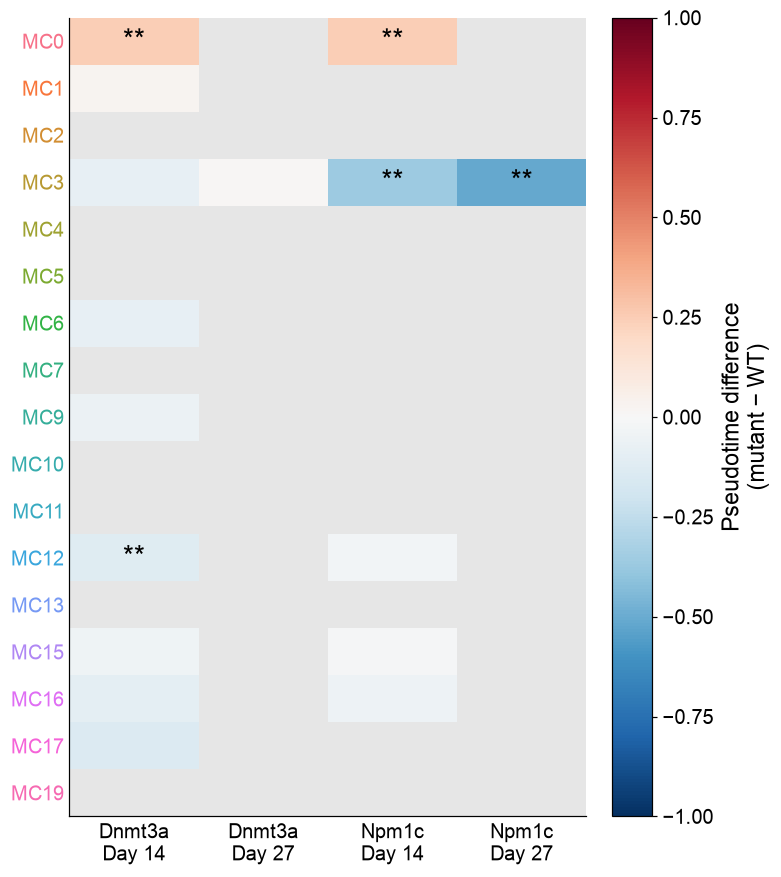

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/lineage_mk_state_response


In [7]:

branch='Mk'
plot=B.loc[B.branch.eq(branch)].copy()
matrix=plot.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=COLUMNS)
qmatrix=plot.pivot(index='mc',columns=['mutant','day'],values='q_340').reindex(index=MCS,columns=COLUMNS)
point=plot.pivot(index='mc',columns=['mutant','day'],values='point_estimable').reindex(index=MCS,columns=COLUMNS)
inference=plot.pivot(index='mc',columns=['mutant','day'],values='inference_estimable').reindex(index=MCS,columns=COLUMNS)
hatch=point & ~inference
assert np.array_equal(matrix.notna().to_numpy(),point.to_numpy())
before=set(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.3,8.2))
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        value=matrix.iloc[i,j]
        if hatch.iloc[i,j]:
            ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='none',edgecolor='white' if abs(value)>.55 else '#333333',hatch='////',linewidth=.7,zorder=3))
        qvalue=qmatrix.iloc[i,j]
        if pd.notna(qvalue) and qvalue<.1:
            ax.text(j,i,'**' if qvalue<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(value)>.55 else 'black',zorder=4)
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27'])
ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc])
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
assert len(ax.patches)==int(hatch.to_numpy().sum())
assert len(ax.texts)==int((qmatrix<.1).to_numpy().sum())
assert im.get_clim()==(-1,1) and len(set(plt.get_fignums())-before)==1
matrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_effects.csv')
qmatrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_q340.csv')
hatch.to_csv(O/f'tables/lineage_{branch.lower()}_hatched_cells.csv')
fig.tight_layout();stem=O/'panels/lineage_mk_state_response'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


### Erythroid

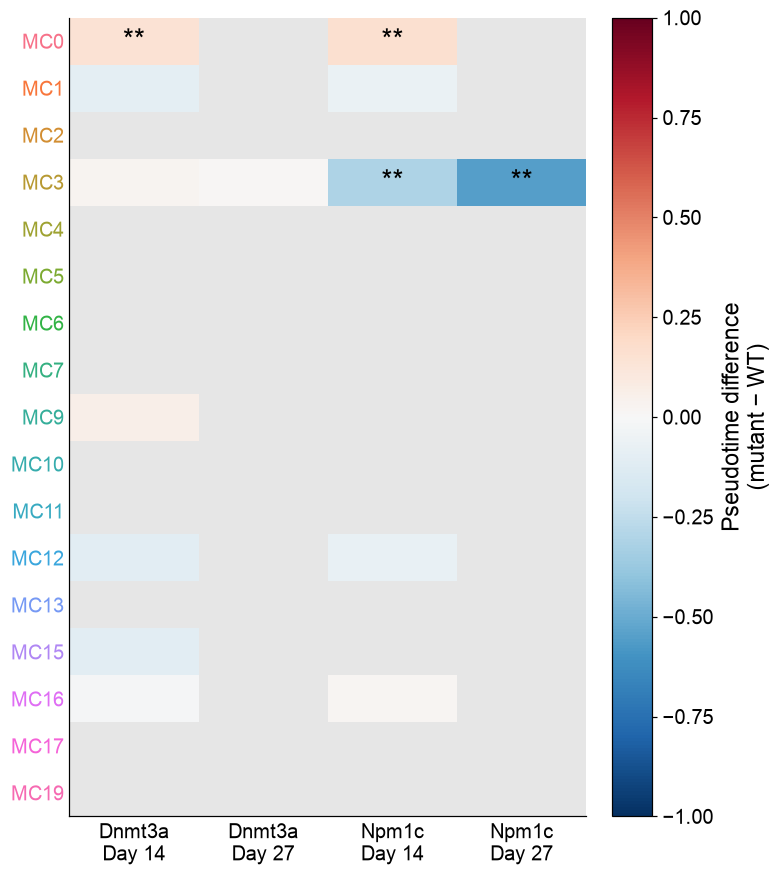

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/lineage_ery_state_response


In [8]:

branch='Ery'
plot=B.loc[B.branch.eq(branch)].copy()
matrix=plot.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=COLUMNS)
qmatrix=plot.pivot(index='mc',columns=['mutant','day'],values='q_340').reindex(index=MCS,columns=COLUMNS)
point=plot.pivot(index='mc',columns=['mutant','day'],values='point_estimable').reindex(index=MCS,columns=COLUMNS)
inference=plot.pivot(index='mc',columns=['mutant','day'],values='inference_estimable').reindex(index=MCS,columns=COLUMNS)
hatch=point & ~inference
assert np.array_equal(matrix.notna().to_numpy(),point.to_numpy())
before=set(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.3,8.2))
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        value=matrix.iloc[i,j]
        if hatch.iloc[i,j]:
            ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='none',edgecolor='white' if abs(value)>.55 else '#333333',hatch='////',linewidth=.7,zorder=3))
        qvalue=qmatrix.iloc[i,j]
        if pd.notna(qvalue) and qvalue<.1:
            ax.text(j,i,'**' if qvalue<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(value)>.55 else 'black',zorder=4)
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27'])
ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc])
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
assert len(ax.patches)==int(hatch.to_numpy().sum())
assert len(ax.texts)==int((qmatrix<.1).to_numpy().sum())
assert im.get_clim()==(-1,1) and len(set(plt.get_fignums())-before)==1
matrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_effects.csv')
qmatrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_q340.csv')
hatch.to_csv(O/f'tables/lineage_{branch.lower()}_hatched_cells.csv')
fig.tight_layout();stem=O/'panels/lineage_ery_state_response'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


### Basophil

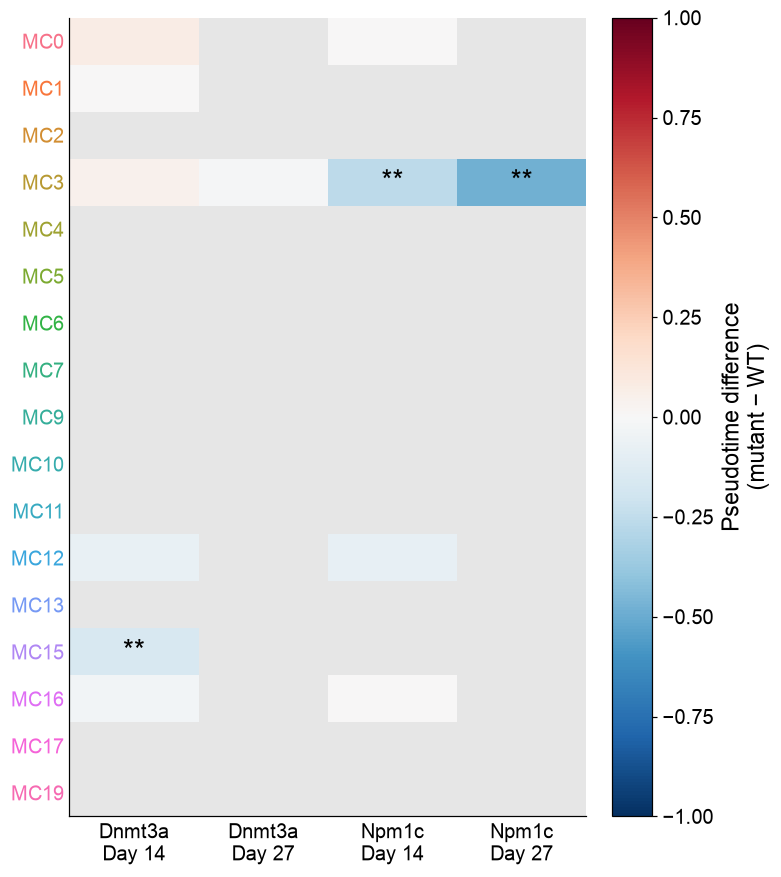

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/lineage_baso_state_response


In [9]:

branch='Baso'
plot=B.loc[B.branch.eq(branch)].copy()
matrix=plot.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=COLUMNS)
qmatrix=plot.pivot(index='mc',columns=['mutant','day'],values='q_340').reindex(index=MCS,columns=COLUMNS)
point=plot.pivot(index='mc',columns=['mutant','day'],values='point_estimable').reindex(index=MCS,columns=COLUMNS)
inference=plot.pivot(index='mc',columns=['mutant','day'],values='inference_estimable').reindex(index=MCS,columns=COLUMNS)
hatch=point & ~inference
assert np.array_equal(matrix.notna().to_numpy(),point.to_numpy())
before=set(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.3,8.2))
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        value=matrix.iloc[i,j]
        if hatch.iloc[i,j]:
            ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='none',edgecolor='white' if abs(value)>.55 else '#333333',hatch='////',linewidth=.7,zorder=3))
        qvalue=qmatrix.iloc[i,j]
        if pd.notna(qvalue) and qvalue<.1:
            ax.text(j,i,'**' if qvalue<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(value)>.55 else 'black',zorder=4)
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27'])
ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc])
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
assert len(ax.patches)==int(hatch.to_numpy().sum())
assert len(ax.texts)==int((qmatrix<.1).to_numpy().sum())
assert im.get_clim()==(-1,1) and len(set(plt.get_fignums())-before)==1
matrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_effects.csv')
qmatrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_q340.csv')
hatch.to_csv(O/f'tables/lineage_{branch.lower()}_hatched_cells.csv')
fig.tight_layout();stem=O/'panels/lineage_baso_state_response'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


### Neutrophil

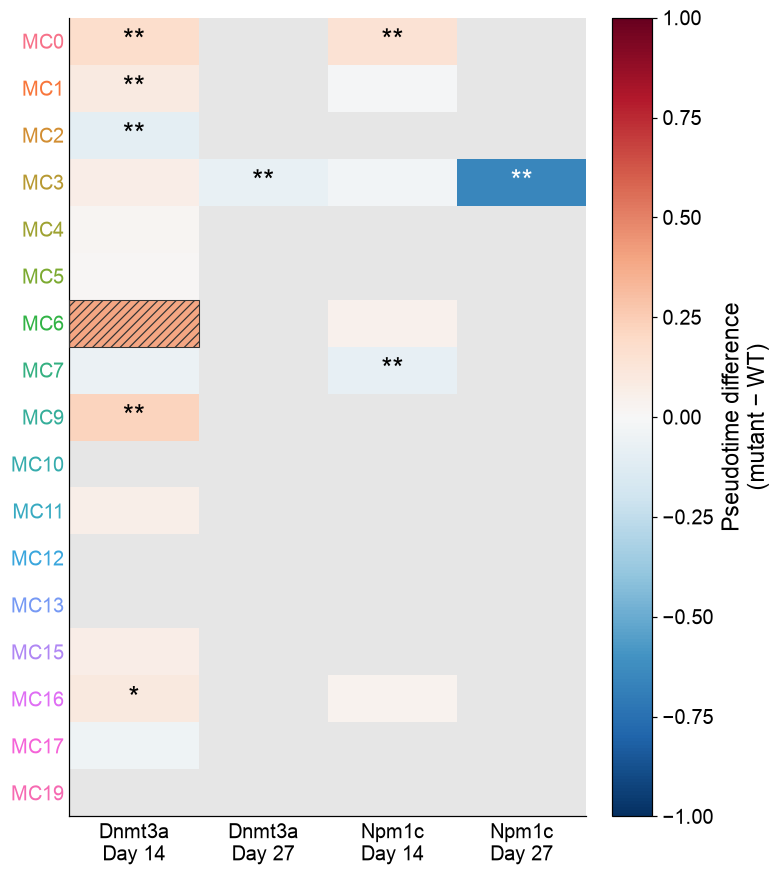

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/lineage_neu_state_response


In [10]:

branch='Neu'
plot=B.loc[B.branch.eq(branch)].copy()
matrix=plot.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=COLUMNS)
qmatrix=plot.pivot(index='mc',columns=['mutant','day'],values='q_340').reindex(index=MCS,columns=COLUMNS)
point=plot.pivot(index='mc',columns=['mutant','day'],values='point_estimable').reindex(index=MCS,columns=COLUMNS)
inference=plot.pivot(index='mc',columns=['mutant','day'],values='inference_estimable').reindex(index=MCS,columns=COLUMNS)
hatch=point & ~inference
assert np.array_equal(matrix.notna().to_numpy(),point.to_numpy())
before=set(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.3,8.2))
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        value=matrix.iloc[i,j]
        if hatch.iloc[i,j]:
            ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='none',edgecolor='white' if abs(value)>.55 else '#333333',hatch='////',linewidth=.7,zorder=3))
        qvalue=qmatrix.iloc[i,j]
        if pd.notna(qvalue) and qvalue<.1:
            ax.text(j,i,'**' if qvalue<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(value)>.55 else 'black',zorder=4)
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27'])
ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc])
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
assert len(ax.patches)==int(hatch.to_numpy().sum())
assert len(ax.texts)==int((qmatrix<.1).to_numpy().sum())
assert im.get_clim()==(-1,1) and len(set(plt.get_fignums())-before)==1
matrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_effects.csv')
qmatrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_q340.csv')
hatch.to_csv(O/f'tables/lineage_{branch.lower()}_hatched_cells.csv')
fig.tight_layout();stem=O/'panels/lineage_neu_state_response'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


### Monocyte

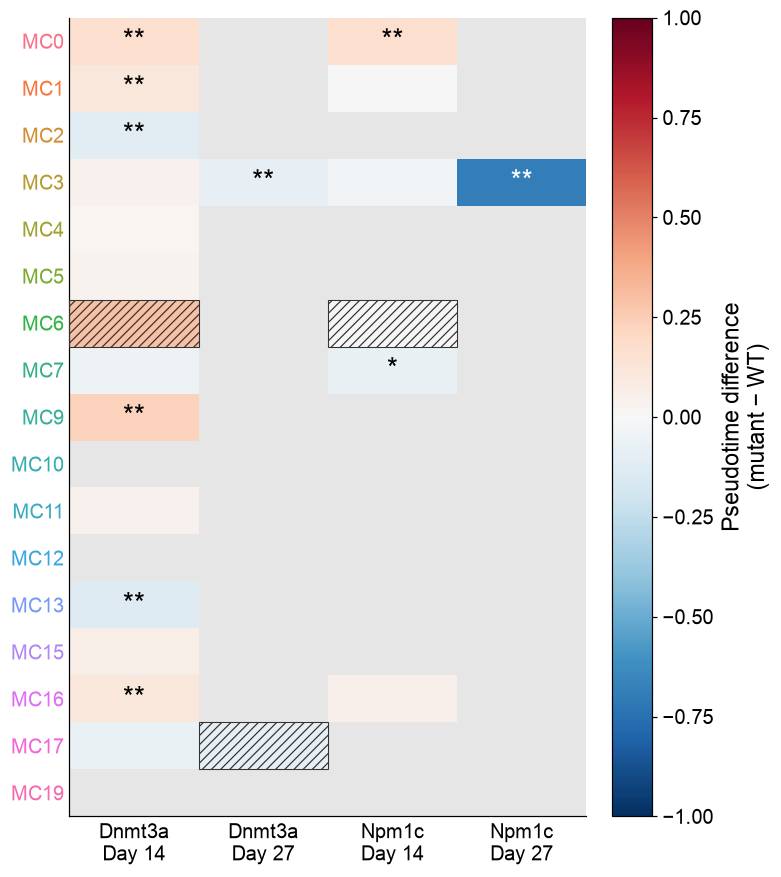

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/lineage_mono_state_response


In [11]:

branch='Mono'
plot=B.loc[B.branch.eq(branch)].copy()
matrix=plot.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=COLUMNS)
qmatrix=plot.pivot(index='mc',columns=['mutant','day'],values='q_340').reindex(index=MCS,columns=COLUMNS)
point=plot.pivot(index='mc',columns=['mutant','day'],values='point_estimable').reindex(index=MCS,columns=COLUMNS)
inference=plot.pivot(index='mc',columns=['mutant','day'],values='inference_estimable').reindex(index=MCS,columns=COLUMNS)
hatch=point & ~inference
assert np.array_equal(matrix.notna().to_numpy(),point.to_numpy())
before=set(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.3,8.2))
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        value=matrix.iloc[i,j]
        if hatch.iloc[i,j]:
            ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='none',edgecolor='white' if abs(value)>.55 else '#333333',hatch='////',linewidth=.7,zorder=3))
        qvalue=qmatrix.iloc[i,j]
        if pd.notna(qvalue) and qvalue<.1:
            ax.text(j,i,'**' if qvalue<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(value)>.55 else 'black',zorder=4)
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27'])
ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
for tick,mc in zip(ax.get_yticklabels(),MCS):tick.set_color(MC_COLORS[mc])
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
assert len(ax.patches)==int(hatch.to_numpy().sum())
assert len(ax.texts)==int((qmatrix<.1).to_numpy().sum())
assert im.get_clim()==(-1,1) and len(set(plt.get_fignums())-before)==1
matrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_effects.csv')
qmatrix.to_csv(O/f'tables/lineage_{branch.lower()}_displayed_q340.csv')
hatch.to_csv(O/f'tables/lineage_{branch.lower()}_hatched_cells.csv')
fig.tight_layout();stem=O/'panels/lineage_mono_state_response'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


## MC3 forest panels with the same global correction
These copies preserve the existing MC3 point estimates, pointwise confidence intervals, order, scales, colors and markers. Only the star source is changed from the superseded 20-test q values to the single global 340-test family used throughout this notebook. No new tests are added. The original MC3 source tables and panels remain unchanged.

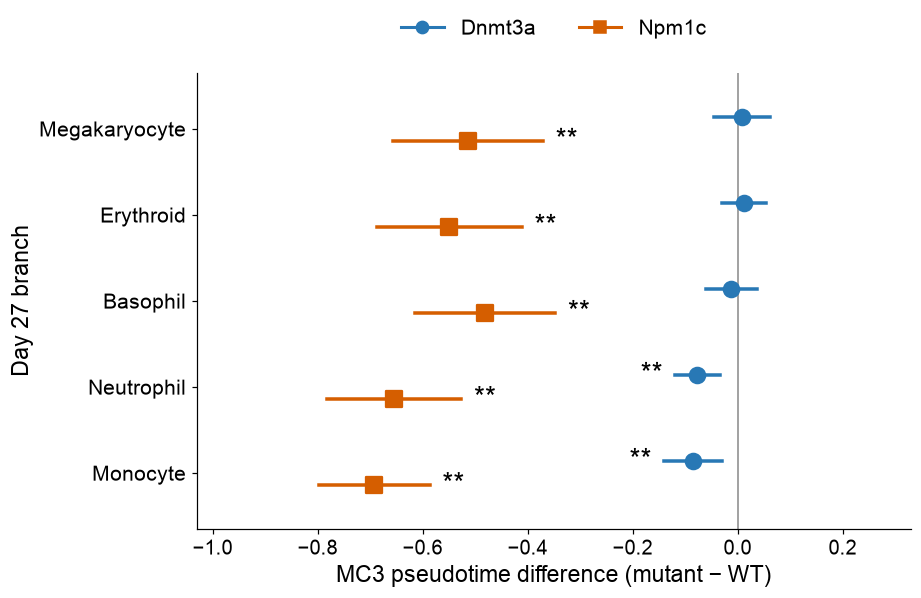

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/figure_6f_mc3_day27_branch_state_q340


In [12]:

plot=B.loc[B.mc.eq('3') & B.day.eq('D27')].copy()
plot['position']=plot.branch.map({b:i for i,b in enumerate(BRANCHES)})
assert len(plot)==10 and plot.inference_estimable.all()
fig,ax=plt.subplots(figsize=(8.6,5.7));ax.axvline(0,color='#888888',lw=1)
for row in plot.itertuples():
    y=row.position+(-.14 if row.mutant=='Dnmt3a' else .14);marker='o' if row.mutant=='Dnmt3a' else 's'
    if row.inference_estimable:ax.plot([row.ci_low,row.ci_high],[y,y],color=COLORS[row.mutant],lw=2.3)
    if row.point_estimable:ax.scatter(row.dpsi,y,s=100,marker=marker,edgecolor=COLORS[row.mutant],facecolor=COLORS[row.mutant] if row.inference_estimable else 'white',linewidth=1.5,zorder=3)
    if pd.notna(row.q_340) and row.q_340<.1:
        label_x=row.ci_high+.024;near_zero=(-.055<label_x<.035)
        ax.text(row.ci_low-.024 if near_zero else label_x,y,'**' if row.q_340<.05 else '*',va='center',ha='right' if near_zero else 'left',fontsize=18)
ax.set_yticks(range(5),[NAMES[b] for b in BRANCHES]);ax.invert_yaxis();ax.set_ylim(4.65,-.65);ax.set_xlim(-1.03,.33)
ax.tick_params(axis='y',labelsize=14)
ax.set_xlabel('MC3 pseudotime difference (mutant − WT)');ax.set_ylabel('Day 27 branch')
handles=[Line2D([],[],color=COLORS[a],marker='o' if a=='Dnmt3a' else 's',lw=2,markersize=8,label=a) for a in MUTANTS]
ax.legend(handles=handles,frameon=False,loc='upper center',bbox_to_anchor=(.5,1.16),ncol=2)
assert len(ax.texts)==int(plot.q_340.lt(.1).sum())
plot.to_csv(O/'tables/figure_6f_mc3_day27_branch_state_q340_displayed_effects.csv',index=False)
fig.tight_layout();stem=O/'panels/figure_6f_mc3_day27_branch_state_q340'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


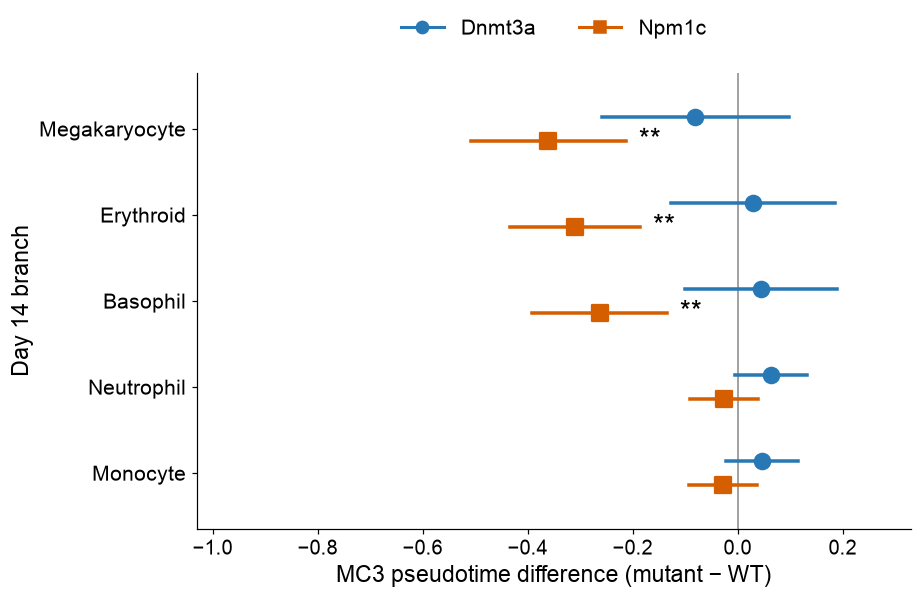

/path/to/ChronoClone/analysis_workspace/singh/singh_lineage_state_responses_20260911/panels/figure_s6b_mc3_day14_branch_state_q340


In [13]:

plot=B.loc[B.mc.eq('3') & B.day.eq('D14')].copy()
plot['position']=plot.branch.map({b:i for i,b in enumerate(BRANCHES)})
assert len(plot)==10 and plot.inference_estimable.all()
fig,ax=plt.subplots(figsize=(8.6,5.7));ax.axvline(0,color='#888888',lw=1)
for row in plot.itertuples():
    y=row.position+(-.14 if row.mutant=='Dnmt3a' else .14);marker='o' if row.mutant=='Dnmt3a' else 's'
    if row.inference_estimable:ax.plot([row.ci_low,row.ci_high],[y,y],color=COLORS[row.mutant],lw=2.3)
    if row.point_estimable:ax.scatter(row.dpsi,y,s=100,marker=marker,edgecolor=COLORS[row.mutant],facecolor=COLORS[row.mutant] if row.inference_estimable else 'white',linewidth=1.5,zorder=3)
    if pd.notna(row.q_340) and row.q_340<.1:
        label_x=row.ci_high+.024;near_zero=(-.055<label_x<.035)
        ax.text(row.ci_low-.024 if near_zero else label_x,y,'**' if row.q_340<.05 else '*',va='center',ha='right' if near_zero else 'left',fontsize=18)
ax.set_yticks(range(5),[NAMES[b] for b in BRANCHES]);ax.invert_yaxis();ax.set_ylim(4.65,-.65);ax.set_xlim(-1.03,.33)
ax.tick_params(axis='y',labelsize=14)
ax.set_xlabel('MC3 pseudotime difference (mutant − WT)');ax.set_ylabel('Day 14 branch')
handles=[Line2D([],[],color=COLORS[a],marker='o' if a=='Dnmt3a' else 's',lw=2,markersize=8,label=a) for a in MUTANTS]
ax.legend(handles=handles,frameon=False,loc='upper center',bbox_to_anchor=(.5,1.16),ncol=2)
assert len(ax.texts)==int(plot.q_340.lt(.1).sum())
plot.to_csv(O/'tables/figure_s6b_mc3_day14_branch_state_q340_displayed_effects.csv',index=False)
fig.tight_layout();stem=O/'panels/figure_s6b_mc3_day14_branch_state_q340'
fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight',metadata={'Date':'2026-09-11'})
fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight')
plt.show();print(stem)


## Validation and generated-file registry

In [14]:

assert all(sha(ROOT/p)==h for p,h in source_hashes.items())
import nbformat, xml.etree.ElementTree as ET
saved=nbformat.read(O/'0001_lineage_state_responses.ipynb',as_version=4)
plot_cells=[c for c in saved.cells if c.cell_type=='code' and any(isinstance(n,ast.Call) and isinstance(n.func,ast.Attribute) and isinstance(n.func.value,ast.Name) and n.func.value.id=='plt' and n.func.attr=='subplots' for n in ast.walk(ast.parse(c.source)))]
assert len(plot_cells)==7
for c in plot_cells:
    assert c.source.count('plt.subplots(')==1 and c.source.count("stem.with_suffix('.svg')")==1
    assert 'plot=B.loc' in c.source and 'plt.show()' in c.source and '.set_title(' not in c.source
    assert 'q_340' in c.source and 'q_20' not in c.source
for p in (O/'panels').glob('*.svg'):
    assert len(ET.parse(p).findall('.//{http://www.w3.org/2000/svg}text'))>=10
outputs=pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':sha(p),'bytes':p.stat().st_size} for folder in ['tables','panels'] for p in sorted((O/folder).glob('*')) if p.is_file()])
outputs.to_csv(O/'reports/output_manifest.csv',index=False)
summary={'planned_tests':len(B),'BH_family':340,'point_estimable':int(B.point_estimable.sum()),'inference_estimable':int(B.inference_estimable.sum()),'point_only':int(B.point_only.sum()),'q_lt_005':int(B.q_340.lt(.05).sum()),'q_lt_010':int(B.q_340.lt(.1).sum()),'mc3_raw_comparisons_reproduced':len(reconciliation),'maximum_mc3_effect_difference':float(reconciliation.effect_abs_difference.max()),'maximum_mc3_p_difference':float(reconciliation.p_abs_difference.max()),'source_hashes_unchanged':True,'no_embedding_or_mask_refit':True,'no_expression_access':True,'family_dependence_preserved':True,'branch_masks_overlap':True,'one_inline_plot_per_cell':True,'environment':environment}
visual_file=O/'reports/visual_review_decisions.json'
summary['visual_review']='pending'
if visual_file.exists():
    reviewed=json.loads(visual_file.read_text())
    assert len(reviewed['panels'])==7
    for row in reviewed['panels']:
        assert row['status']=='pass' and row['individually_viewed'] and sha(ROOT/row['path'])==row['sha256']
    summary['visual_review']='pass'
(O/'reports/results_summary.json').write_text(json.dumps(summary,indent=2))
display(summary)
display(outputs.loc[outputs.path.str.contains('/panels/')])


{'planned_tests': 340,
 'BH_family': 340,
 'point_estimable': 86,
 'inference_estimable': 82,
 'point_only': 4,
 'q_lt_005': 29,
 'q_lt_010': 31,
 'mc3_raw_comparisons_reproduced': 20,
 'maximum_mc3_effect_difference': 8.673617379884035e-17,
 'maximum_mc3_p_difference': 0.0,
 'source_hashes_unchanged': True,
 'no_embedding_or_mask_refit': True,
 'no_expression_access': True,
 'family_dependence_preserved': True,
 'branch_masks_overlap': True,
 'one_inline_plot_per_cell': True,
 'environment': {'name': 'chronoclone',
  'manager': 'existing Conda-managed installation; unchanged',
  'path': '/path/to/ChronoClone/.runtime/chronoclone',
  'kernel': 'chronoclone',
  'Python': '3.11.15',
  'versions': {'numpy': '2.4.6',
   'pandas': '2.3.3',
   'scipy': '1.17.1',
   'statsmodels': '0.14.6',
   'matplotlib': '3.11.0',
   'nbformat': '5.10.4',
   'nbclient': '0.11.0'},
  'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/singh/sing

,path,sha256,bytes
27,analysis_workspace/singh/singh_lineage_state_respon...,eaf874dbd6e281b864d2abb45ff769e6e38d0c38ba61b0...,80015
28,analysis_workspace/singh/singh_lineage_state_respon...,00a2bf4bfc713e2f3c4f1a17c0b15a172d96aca9225b95...,15265
29,analysis_workspace/singh/singh_lineage_state_respon...,6edfcc902a3dcb164082b4cc9e3f7196187f17ed32c072...,77150
30,analysis_workspace/singh/singh_lineage_state_respon...,4c41494789ca4a048e632c2dcff9897bcbbe7f677d4824...,14516
31,analysis_workspace/singh/singh_lineage_state_respon...,70a11a03cc2298d38744d02864a0ac994bed8494687f23...,118921
32,analysis_workspace/singh/singh_lineage_state_respon...,60388d93159ab31943dfe5ae0bcfa0a65f4c097f0881a0...,19475
33,analysis_workspace/singh/singh_lineage_state_respon...,37395e8bd1160555a014e8650ccfb8fce6314cfea45e72...,119785
34,analysis_workspace/singh/singh_lineage_state_respon...,99a73ed22391bc360be1c9657564b6201517cf73428e8a...,19721
35,analysis_workspace/singh/singh_lineage_state_respon...,d43a87ba41c187e7369d1924e0076631fedb12d14c9448...,120563
36,analysis_workspace/singh/singh_lineage_state_respon...,28146eeb4a409767372479f0a9b1ccc0ccb11fbeca00b6...,19933
